In [345]:
import torch
from typing import Sequence, Dict
import matplotlib.pyplot as plt

In [ ]:

def lorenz63(xyz, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = xyz[..., 0], xyz[..., 1], xyz[..., 2]
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return torch.stack([dx, dy, dz], dim=-1)

def rk4_step(func, state, dt, **kwargs):
    k1 = func(state, **kwargs)
    k2 = func(state + 0.5 * dt * k1, **kwargs)
    k3 = func(state + 0.5 * dt * k2, **kwargs)
    k4 = func(state + dt * k3, **kwargs)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def generate_lorenz63(n_steps=10000, dt=0.01, 
                      sigma=10.0, rho=28.0, beta=8/3,
                      device="cpu"):
    # initial condition
    state = torch.tensor([[1.0, 1.0, 1.0]], device=device)
    traj = [state]
    for _ in range(n_steps):
        state = rk4_step(lorenz63, state, dt, sigma=sigma, rho=rho, beta=beta)
        traj.append(state)
    return torch.cat(traj)

# Example usage
if __name__ == "__main__":
    burnin = 200 
    traj = generate_lorenz63(n_steps=10000+burnin, dt=0.01)
    print(traj.shape)  # (10001, 3)

torch.Size([10201, 3])


In [347]:
def rbf_kernel(X: torch.Tensor, Y: torch.Tensor, lengthscale: float = 1.0, variance: float = 1.0) -> torch.Tensor:
    """
    Radial Basis Function (Gaussian) kernel supporting broadcasting:
      X: (..., d), Y: (..., d) -> output: broadcasted leading shape
    """
    # X, Y are broadcast to a common shape (..., d)
    diff = X - Y
    sqdist = (diff * diff).sum(dim=-1)
    ls2 = (float(lengthscale) ** 2) + 1e-12
    return float(variance) * torch.exp(-0.5 * sqdist / ls2)

def additive_rbf_kernel(
    X: torch.Tensor,
    Y: torch.Tensor,
    lengthscales: Sequence[float],
    variances: Sequence[float],
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Additive RBF kernel: a linear combination of multiple Gaussian kernels
      k(x,y) = Σ_m variances[m] * exp( -0.5 * ||x - y||^2 / lengthscales[m]^2 )

    Parameters
    ----------
    X, Y : (N, d) tensors (broadcastable inputs)
        Input arrays of points.
    lengthscales : list or 1D tensor of floats
        Lengthscales ℓ_m for each component.
    variances : list or 1D tensor of floats
        Variances σ_m² for each component.
    eps : float
        Small constant to stabilize divisions.

    Returns
    -------
    K : (N, M) tensor
        Kernel matrix between all pairs of rows in X and Y.
    """
    X = torch.as_tensor(X)
    Y = torch.as_tensor(Y)
    device, dtype = X.device, X.dtype

    lengthscales = torch.as_tensor(lengthscales, dtype=dtype, device=device)
    variances = torch.as_tensor(variances, dtype=dtype, device=device)
    assert lengthscales.shape == variances.shape, "lengthscales and variances must have same length"

    diff = X[:, None, :] - Y[None, :, :]     # (N, M, d)
    sqdist = (diff ** 2).sum(dim=-1, keepdim=False)  # (N, M)

    # Vectorized additive sum over all components
    K = torch.zeros_like(sqdist)
    for ℓ, σ2 in zip(lengthscales, variances):
        K += σ2 * torch.exp(-0.5 * sqdist / (ℓ ** 2 + eps))
    return K

In [348]:
def make_delay_matrix(v_train: torch.Tensor, tau: int):
    train_size = v_train.numel()
    assert tau < train_size, "tau must be smaller than train_size"

    # reverse the series to make slicing easier
    v_rev = torch.flip(v_train, dims=[0])

    # build a list of shifted versions
    X = torch.stack([v_rev[i : i + train_size - tau] for i in range(tau + 1)], dim=1)

    # X has rows corresponding to reversed indexing, so flip rows back
    X = torch.flip(X, dims=[0])
    return X


In [474]:
burnin = 500
dt = 0.01
n_tot = 10000
train_size = 5000
v_train = traj[burnin:burnin+train_size,0]
v_test = traj[burnin+train_size:burnin+train_size+n_tot+1,0]
tau = 100
eta_train = 0*torch.randn(train_size-tau)/10
eta_test = 0*torch.randn(len(v_test))/10
train_times = dt*torch.arange(burnin,burnin+train_size)
test_times = dt*torch.arange(burnin+train_size,burnin+n_tot+1-300)
Y_train = (traj[burnin+1+tau:burnin+1+train_size,0]-traj[burnin+tau:burnin+train_size,0]-dt*eta_train)/dt

In [475]:
torch.arange(burnin+train_size,burnin+n_tot+1).shape

torch.Size([5001])

In [476]:
v_test.shape

torch.Size([4701])

In [477]:
test_times.shape

torch.Size([4701])

In [478]:
def gaussian_kernel(x, y, sigma=1.0):
    """
    Computes standard Gaussian (RBF) kernel between two 1D tensors x and y.
    Returns a matrix of shape (len(x), len(y)).
    """
    x = x.unsqueeze(1)  # (n,1)
    y = y.unsqueeze(0)  # (1,m)
    return torch.exp(-0.5 * (x - y)**2 / sigma**2)


In [479]:
def G_single(v, s, w, t, sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0):
    """
    Computes scalar G((v,s),(w,t)) for matching 1D vectors v,w,s,t (each length tau+1).
    """
    # First term
    G_F = torch.exp(-0.5 * (v[0] - w[0])**2 / sigma_F**2)

    # Reverse for K2 part
    v_flip = torch.flip(v, dims=[0])
    w_flip = torch.flip(w, dims=[0])

    K1 = gaussian_kernel(s, t, sigma_K1)
    K2 = gaussian_kernel(v_flip, w_flip, sigma_K2)

    return G_F + torch.sum(K1 * K2)


def G_MATRIX(V, W, S, T, sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0):
    """
    Full Gram matrix: shape (N, M)
    """
    N, _ = V.shape
    M, _ = W.shape

    # Expand for pairwise combinations
    v_exp = V[:, None, :]       # (N, 1, tau+1)
    w_exp = W[None, :, :]       # (1, M, tau+1)
    s_exp = S[:, None, :]
    t_exp = T[None, :, :]

    # G_F term (pairwise between v0 and w0)
    G_F = torch.exp(-0.5 * (v_exp[..., 0] - w_exp[..., 0])**2 / sigma_F**2)  # (N, M)

    # Flipped for K2
    v_flip = torch.flip(v_exp, dims=[-1])
    w_flip = torch.flip(w_exp, dims=[-1])

    # Compute all K1 and K2 (N, M, τ+1, τ+1)

    K1 = torch.exp(-0.5 * (s_exp.unsqueeze(-2) - t_exp.unsqueeze(-3))**2 / sigma_K1**2)
    K2 = torch.exp(-0.5 * (v_flip.unsqueeze(-2) - w_flip.unsqueeze(-3))**2 / sigma_K2**2)

    # Sum over last two axes to get scalar per (N,M) pair
    sum_term = torch.sum(K1 * K2, dim=(-2, -1))

    return G_F + sum_term


In [480]:
def kernel_ridge_regression(X_train, S_train, Y_train, 
                            X_test, S_test,
                            sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0, 
                            reg_lambda=1e-6):
    """
    Compute Kernel Ridge Regression prediction using custom kernel G_MATRIX.
    
    Args:
        X_train: (N, tau+1)
        S_train: (N, tau+1)
        Y_train: (N,) or (N, d)
        X_test:  (M, tau+1)
        S_test:  (M, tau+1)
        reg_lambda: regularization parameter (λ)
        
    Returns:
        Y_pred: (M,) or (M, d)
    """
    N = X_train.shape[0]

    # ----- Kernel matrices -----
    K_train = G_MATRIX(X_train, X_train, S_train, S_train,
                       sigma_F, sigma_K1, sigma_K2)  # (N, N)
    K_cross = G_MATRIX(X_test, X_train, S_test, S_train,
                       sigma_F, sigma_K1, sigma_K2)  # (M, N)

    # ----- Regularization and solve -----
    I = torch.eye(N, device=X_train.device, dtype=X_train.dtype)
    A = K_train + reg_lambda * I

    # Solve for alpha = A^{-1} Y_train
    # Use Cholesky or torch.linalg.solve for stability
    alpha = torch.linalg.solve(A, Y_train)

    # ----- Prediction -----
    Y_pred = K_cross @ alpha
    return Y_pred

In [481]:
X = make_delay_matrix(v_train,tau)
T = make_delay_matrix(train_times,tau)

In [482]:
X_test = make_delay_matrix(v_test,tau)
T_test = make_delay_matrix(test_times,tau)

In [483]:
Y_train.shape

torch.Size([4900])

In [484]:
X.shape

torch.Size([4900, 101])

In [485]:
T.shape

torch.Size([4900, 101])

In [486]:
X_test.shape

torch.Size([4601, 101])

In [487]:
T_test.shape

torch.Size([4601, 101])

In [488]:
Y_pred = kernel_ridge_regression(X,T,Y_train, X_test, T_test,
                                 sigma_F=1, sigma_K1=1, sigma_K2=1, reg_lambda=1e-0)

KeyboardInterrupt: 

In [ ]:
len(v_test)

4701

In [471]:
v_pred = torch.zeros(len(v_test))
v_pred[0] = v_train[-1]+dt*Y_pred[0]+dt*eta_test[0]

In [472]:
for i in range(tau,len(v_test)-tau):
    v_pred[i] = v_pred[i-1]+dt*Y_pred[i-tau]+dt*eta_test[i-tau]

/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_19152/3986364975.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


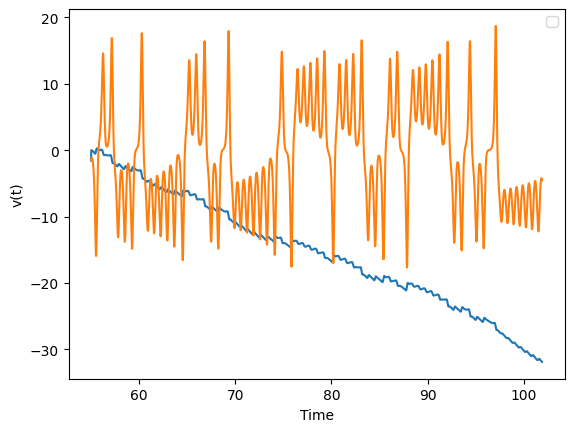

In [473]:
plt.plot(test_times[:-tau], v_pred[:-tau])
plt.plot(test_times[:-tau], v_test[:-tau])
plt.xlabel('Time')
plt.ylabel('v(t)')
plt.legend()
plt.show()

In [427]:
v_pred

tensor([-1.5553,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000])